In [1]:
# Experiment 04 — Bell-State Simulation and Measurement Histogram

In [2]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

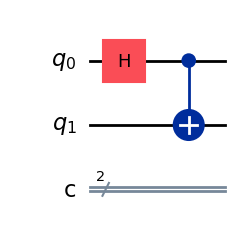

In [3]:
# Create a circuit with two qubits
qc = QuantumCircuit(2, 2)

# Apply Hadamard and CNOT gates
qc.h(0)
qc.cx(0, 1)

# Display the circuit
display(qc.draw("mpl"))

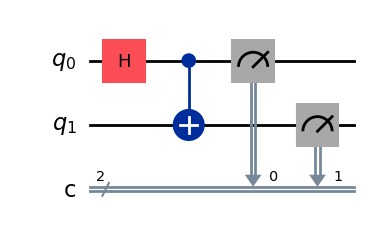

Measurement Counts: {'00': 521, '11': 503}


In [4]:
# Add measurements to both qubits
qc.measure([0, 1], [0, 1])

# Display the complete circuit
display(qc.draw("mpl"))

# Run the circuit 1024 times
simulator = AerSimulator()

result = simulator.run(
    transpile(qc, simulator),
    shots=1024,
    seed_simulator=42
).result()

counts = result.get_counts()

print("Measurement Counts:", counts)

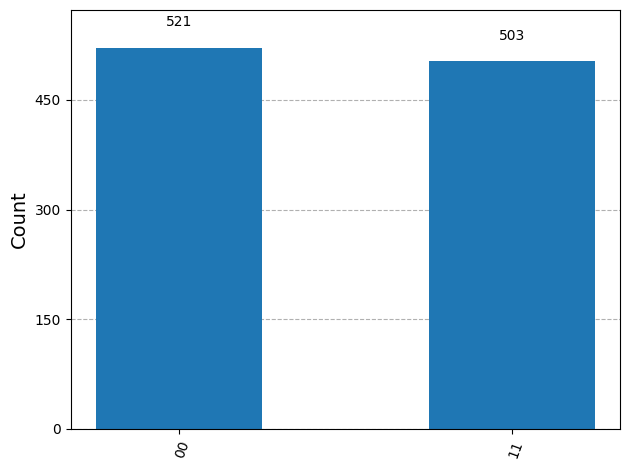

Probability of 00: 0.5087890625
Probability of 11: 0.4912109375


In [5]:
# Plot the measurement counts
display(plot_histogram(counts))

# Calculate the measured probabilities
total = sum(counts.values())

print("Probability of 00:", counts.get("00", 0) / total)
print("Probability of 11:", counts.get("11", 0) / total)

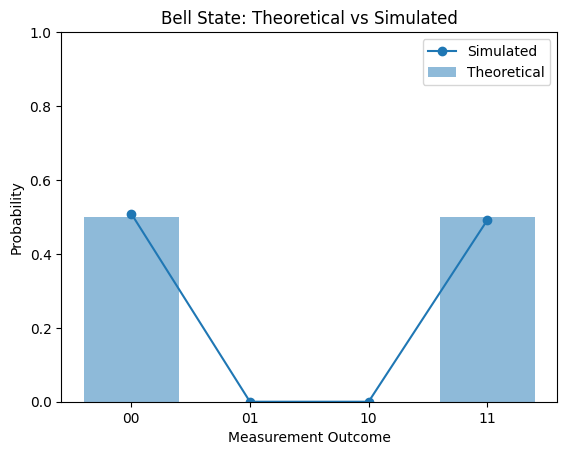

In [6]:
# Compare theoretical and measured probabilities
states = ["00", "01", "10", "11"]

theoretical = [0.5, 0, 0, 0.5]
simulated = [counts.get(s, 0) / total for s in states]

plt.bar(states, theoretical, alpha=0.5, label="Theoretical")
plt.plot(states, simulated, "o-", label="Simulated")

plt.xlabel("Measurement Outcome")
plt.ylabel("Probability")
plt.title("Bell State: Theoretical vs Simulated")
plt.ylim(0, 1)
plt.legend()
plt.show()